In [14]:
# ============================================================
# IT3091 Machine Learning - Assignment
# Project: Early Identification of At-Risk Students Using ML
# Group: 2026-AI-53
# Member: Herath H.M.S.N.W (IT24104159)
# Main Area: Data Understanding & EDA
# Model: Decision Tree
# Track: Guided Data Track | Domain: Education
# Datasets: Student Performance (Math + Portuguese) - UCI ID 320
# ============================================================

# --- Standard imports ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# --- Reproducibility ---
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# --- Sklearn: model selection ---
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score, cross_val_predict,
    RandomizedSearchCV
)

# --- Sklearn: preprocessing ---
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# --- Sklearn: models ---
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree

# --- Sklearn: metrics ---
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve, auc
)

# --- Display settings ---
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

print("Setup complete.")
print("Random seed:", RANDOM_SEED)

Setup complete.
Random seed: 42


In [15]:
# ============================================================
# Download and load both datasets
# ============================================================
!wget -q https://archive.ics.uci.edu/static/public/320/student+performance.zip -O student.zip
!mkdir -p student_data
!unzip -o student.zip -d student_data/ > /dev/null 2>&1
!unzip -o student_data/student.zip -d student_data/ > /dev/null 2>&1
!rm -f student_data/student.zip student_data/.student.zip_old

# Verify
import os
print("Files in student_data/:", os.listdir('student_data/'))

'wget' is not recognized as an internal or external command,
operable program or batch file.
A subdirectory or file -p already exists.
Error occurred while processing: -p.
A subdirectory or file student_data already exists.
Error occurred while processing: student_data.
The system cannot find the path specified.
The system cannot find the path specified.


Files in student_data/: []


'rm' is not recognized as an internal or external command,
operable program or batch file.


In [16]:

from pathlib import Path
import pandas as pd

# Find the project root from the current notebook directory
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

DATA_DIR = PROJECT_ROOT / "data" / "raw"

math_path = DATA_DIR / "student-mat.csv"
port_path = DATA_DIR / "student-por.csv"

print("Project root:", PROJECT_ROOT)
print("Dataset folder:", DATA_DIR)
print("Mathematics CSV exists:", math_path.exists())
print("Portuguese CSV exists:", port_path.exists())

if not math_path.exists() or not port_path.exists():
    raise FileNotFoundError(
        f"Could not find both datasets in {DATA_DIR}. "
        "Check the actual location of the CSV files."
    )

df_math = pd.read_csv(math_path, sep=";")
df_por = pd.read_csv(port_path, sep=";")

print("\nMath dataset shape:", df_math.shape)
print("Portuguese dataset shape:", df_por.shape)


Project root: c:\Users\USER\student-risk-intelligence
Dataset folder: c:\Users\USER\student-risk-intelligence\data\raw
Mathematics CSV exists: True
Portuguese CSV exists: True

Math dataset shape: (395, 33)
Portuguese dataset shape: (649, 33)


 Data Understanding & Target Construction

In [17]:
# ============================================================
# Add target variable (At-Risk = G3 < 10)
# ============================================================
def add_target(df):
    df = df.copy()
    df['at_risk'] = (df['G3'] < 10).astype(int)
    return df

df_math = add_target(df_math)
df_por  = add_target(df_por)

# Class balance check
for name, df in [("Math", df_math), ("Portuguese", df_por)]:
    counts = df['at_risk'].value_counts().sort_index()
    pcts   = df['at_risk'].value_counts(normalize=True).sort_index() * 100
    print(f"\n{name} — Class Balance:")
    print(pd.DataFrame({'Count': counts.values, 'Percentage': pcts.round(2).values},
                       index=['Not-At-Risk', 'At-Risk']))


Math — Class Balance:
             Count  Percentage
Not-At-Risk    265       67.09
At-Risk        130       32.91

Portuguese — Class Balance:
             Count  Percentage
Not-At-Risk    549       84.59
At-Risk        100       15.41


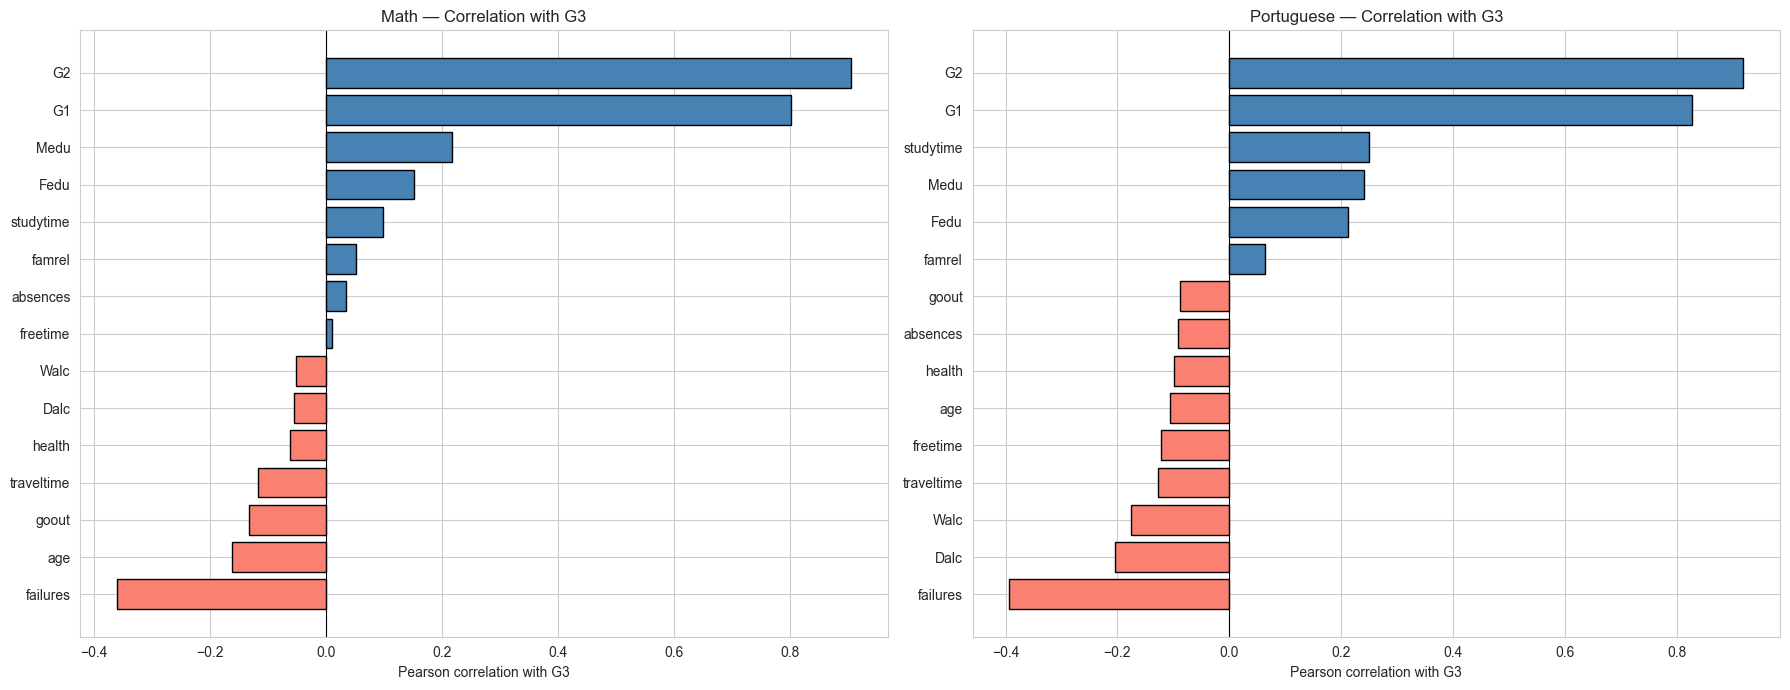


Math — Top 5 correlations with G3:
G2           0.905
G1           0.801
Medu         0.217
Fedu         0.152
studytime    0.098
Name: G3, dtype: float64

Portuguese — Top 5 correlations with G3:
G2           0.919
G1           0.826
studytime    0.250
Medu         0.240
Fedu         0.212
Name: G3, dtype: float64


In [18]:
# ============================================================
# EDA — Correlation with G3 (both datasets)
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, (name, df) in zip(axes, [("Math", df_math), ("Portuguese", df_por)]):
    numeric_cols = df.select_dtypes(include=[np.number]).columns
    corr_g3 = df[numeric_cols].corr()['G3'].drop(['G3', 'at_risk']).sort_values()
    colors = ['salmon' if v < 0 else 'steelblue' for v in corr_g3.values]
    ax.barh(corr_g3.index, corr_g3.values, color=colors, edgecolor='black')
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(f'{name} — Correlation with G3')
    ax.set_xlabel('Pearson correlation with G3')

plt.tight_layout()
plt.show()

# Top 5 features
for name, df in [("Math", df_math), ("Portuguese", df_por)]:
    numeric_cols = df.select_dtypes(include=[np.number]).columns
    top = df[numeric_cols].corr()['G3'].drop(['G3', 'at_risk']).sort_values(ascending=False)
    print(f"\n{name} — Top 5 correlations with G3:")
    print(top.head(5).round(3))

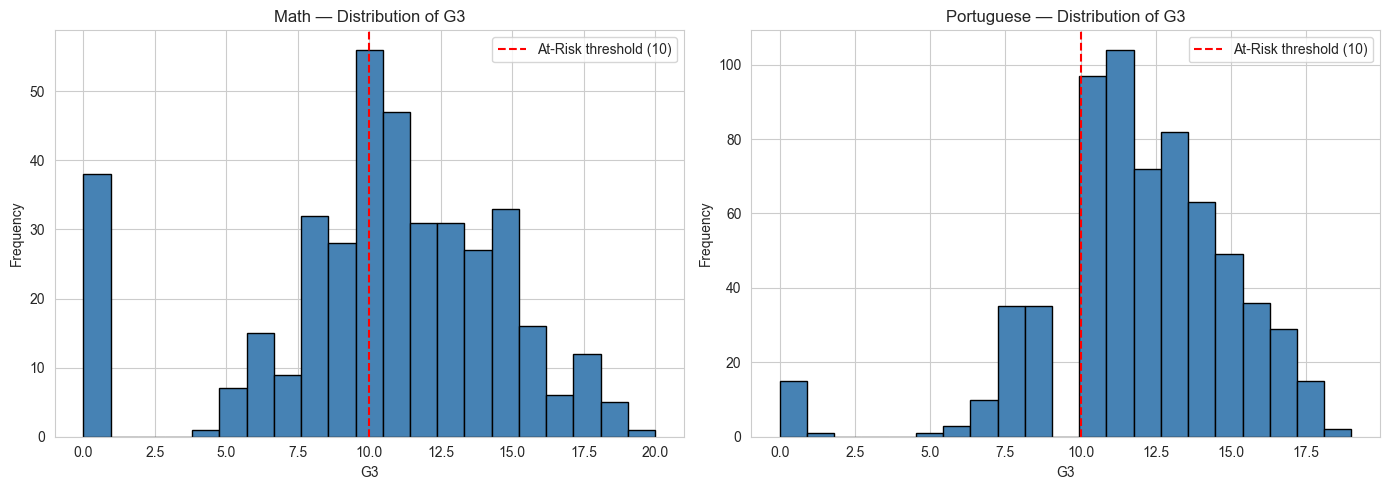

In [19]:
# G3 distribution for both
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, df) in zip(axes, [("Math", df_math), ("Portuguese", df_por)]):
    ax.hist(df['G3'], bins=21, edgecolor='black', color='steelblue')
    ax.axvline(10, color='red', linestyle='--', label='At-Risk threshold (10)')
    ax.set_title(f'{name} — Distribution of G3')
    ax.set_xlabel('G3')
    ax.set_ylabel('Frequency')
    ax.legend()
plt.tight_layout()
plt.show()

In [20]:
# ============================================================
# Preprocessing Pipeline
# ============================================================

# Column type identification
binary_cols = [
    'school', 'sex', 'address', 'famsize', 'Pstatus',
    'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
    'higher', 'internet', 'romantic'
]
nominal_cols = ['Mjob', 'Fjob', 'reason', 'guardian']
ordinal_cols = [
    'Medu', 'Fedu', 'traveltime', 'studytime',
    'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health'
]
numeric_cols = ['age', 'absences', 'failures']
grade_cols   = ['G1', 'G2']

# --- Preprocessing sub-pipelines ---
nominal_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
ordinal_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
])
binary_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder())
])
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# --- Feature Set A preprocessor (no G1/G2) ---
preprocessor_A = ColumnTransformer([
    ('nom', nominal_transformer, nominal_cols),
    ('ord', ordinal_transformer, ordinal_cols),
    ('bin', binary_pipeline, binary_cols),
    ('num', numeric_transformer, numeric_cols),
], remainder='drop')

# --- Feature Set B preprocessor (with G1/G2) ---
numeric_cols_B = numeric_cols + grade_cols
numeric_transformer_B = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
preprocessor_B = ColumnTransformer([
    ('nom', nominal_transformer, nominal_cols),
    ('ord', ordinal_transformer, ordinal_cols),
    ('bin', binary_pipeline, binary_cols),
    ('num', numeric_transformer_B, numeric_cols_B),
], remainder='drop')

# --- Prepare X, y ---
def prepare_Xy(df):
    return df.drop(columns=['G3', 'at_risk']), df['at_risk']

X_por, y_por   = prepare_Xy(df_por)
X_math, y_math = prepare_Xy(df_math)

print(f"Portuguese X shape: {X_por.shape}")
print(f"Math X shape:       {X_math.shape}")
print(f"Feature Set A: 30 features (no G1/G2)")
print(f"Feature Set B: 32 features (with G1/G2)")

Portuguese X shape: (649, 32)
Math X shape:       (395, 32)
Feature Set A: 30 features (no G1/G2)
Feature Set B: 32 features (with G1/G2)


In [21]:
# ============================================================
# Train/Test Split + Stratified 5-fold CV
# ============================================================
TEST_SIZE = 0.20

# Portuguese
X_por_train, X_por_test, y_por_train, y_por_test = train_test_split(
    X_por, y_por, test_size=TEST_SIZE, stratify=y_por, random_state=RANDOM_SEED
)

# Math
X_math_train, X_math_test, y_math_train, y_math_test = train_test_split(
    X_math, y_math, test_size=TEST_SIZE, stratify=y_math, random_state=RANDOM_SEED
)

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

# Threshold range and precision floor (group conventions)
THRESHOLD_RANGE = [0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50]
MIN_PRECISION = 0.30

print("Train/test split summary:")
print(f"  Portuguese: train={len(X_por_train)}, test={len(X_por_test)}")
print(f"  Math:       train={len(X_math_train)}, test={len(X_math_test)}")

Train/test split summary:
  Portuguese: train=519, test=130
  Math:       train=316, test=79


In [22]:
# ============================================================
# Baseline — Majority Class Classifier
# ============================================================
baseline_pipe = Pipeline([
    ('preprocessor', preprocessor_A),
    ('classifier', DummyClassifier(strategy='most_frequent', random_state=RANDOM_SEED))
])
baseline_pipe.fit(X_por_train, y_por_train)
y_pred_baseline = baseline_pipe.predict(X_por_test)
y_proba_baseline = baseline_pipe.predict_proba(X_por_test)[:, 1]

baseline_metrics = {
    'accuracy':  accuracy_score(y_por_test, y_pred_baseline),
    'precision': precision_score(y_por_test, y_pred_baseline, zero_division=0),
    'recall':    recall_score(y_por_test, y_pred_baseline, zero_division=0),
    'f1':        f1_score(y_por_test, y_pred_baseline, zero_division=0),
    'roc_auc':   roc_auc_score(y_por_test, y_proba_baseline),
    'pr_auc':    average_precision_score(y_por_test, y_proba_baseline),
}

print("Baseline — Portuguese, Set A:")
for m, v in baseline_metrics.items():
    print(f"  {m:<10}: {v:.4f}")

Baseline — Portuguese, Set A:
  accuracy  : 0.8462
  precision : 0.0000
  recall    : 0.0000
  f1        : 0.0000
  roc_auc   : 0.5000
  pr_auc    : 0.1538


In [23]:
# ============================================================
# Default Decision Tree (Reference Point)
# ============================================================
dt_default = DecisionTreeClassifier(
    random_state=RANDOM_SEED,
    class_weight='balanced'
)

pipe_dt_default = Pipeline([
    ('preprocessor', preprocessor_A),
    ('classifier', dt_default)
])

# CV scores
cv_pr_auc = cross_val_score(pipe_dt_default, X_por_train, y_por_train,
                             cv=cv_strategy, scoring='average_precision')
cv_roc_auc = cross_val_score(pipe_dt_default, X_por_train, y_por_train,
                              cv=cv_strategy, scoring='roc_auc')

print(f"Default DT — Portuguese, Set A:")
print(f"  CV PR-AUC:  {cv_pr_auc.mean():.4f} (± {cv_pr_auc.std():.4f})")
print(f"  CV ROC-AUC: {cv_roc_auc.mean():.4f} (± {cv_roc_auc.std():.4f})")

# Fit and test
pipe_dt_default.fit(X_por_train, y_por_train)
y_pred_dt_default = pipe_dt_default.predict(X_por_test)
y_proba_dt_default = pipe_dt_default.predict_proba(X_por_test)[:, 1]

dt_default_metrics = {
    'accuracy':  accuracy_score(y_por_test, y_pred_dt_default),
    'precision': precision_score(y_por_test, y_pred_dt_default, zero_division=0),
    'recall':    recall_score(y_por_test, y_pred_dt_default, zero_division=0),
    'f1':        f1_score(y_por_test, y_pred_dt_default, zero_division=0),
    'roc_auc':   roc_auc_score(y_por_test, y_proba_dt_default),
    'pr_auc':    average_precision_score(y_por_test, y_proba_dt_default),
}
print(f"\nTest metrics (threshold=0.5):")
for m, v in dt_default_metrics.items():
    print(f"  {m:<10}: {v:.4f}")

Default DT — Portuguese, Set A:
  CV PR-AUC:  0.2286 (± 0.0585)
  CV ROC-AUC: 0.6038 (± 0.0822)

Test metrics (threshold=0.5):
  accuracy  : 0.7615
  precision : 0.1765
  recall    : 0.1500
  f1        : 0.1622
  roc_auc   : 0.5114
  pr_auc    : 0.1572


In [24]:
# ============================================================
# Decision Tree — Hyperparameter Tuning
# ============================================================

param_dist = {
    'classifier__criterion':         ['gini', 'entropy'],
    'classifier__max_depth':         [None, 3, 5, 7, 10, 15, 20],
    'classifier__min_samples_split': [2, 5, 10, 20],
    'classifier__min_samples_leaf':  [1, 2, 5, 10],
    'classifier__max_features':      [None, 'sqrt', 'log2'],
    'classifier__class_weight':      ['balanced', None],
    'classifier__ccp_alpha':         [0.0, 0.001, 0.005, 0.01],  # pruning
}

pipe_for_tuning = Pipeline([
    ('preprocessor', preprocessor_A),
    ('classifier', DecisionTreeClassifier(random_state=RANDOM_SEED))
])

search = RandomizedSearchCV(
    estimator=pipe_for_tuning,
    param_distributions=param_dist,
    n_iter=60,
    scoring='average_precision',
    cv=cv_strategy,
    random_state=RANDOM_SEED,
    n_jobs=-1,
    verbose=1,
    return_train_score=False
)

print("Starting RandomizedSearchCV (2–4 min)...")
search.fit(X_por_train, y_por_train)

best_params = {k.replace('classifier__', ''): v for k, v in search.best_params_.items()}

print("\nBest Hyperparameters:")
for k, v in best_params.items():
    print(f"  {k}: {v}")
print(f"\nBest CV PR-AUC: {search.best_score_:.4f}")

Starting RandomizedSearchCV (2–4 min)...
Fitting 5 folds for each of 60 candidates, totalling 300 fits

Best Hyperparameters:
  min_samples_split: 20
  min_samples_leaf: 2
  max_features: None
  max_depth: 3
  criterion: entropy
  class_weight: None
  ccp_alpha: 0.005

Best CV PR-AUC: 0.4699


In [25]:
# ============================================================
# Threshold Optimization — Decision Tree
# ============================================================

tuned_pipe = Pipeline([
    ('preprocessor', preprocessor_A),
    ('classifier', DecisionTreeClassifier(random_state=RANDOM_SEED, **best_params))
])

# Out-of-fold probabilities
y_train_proba = cross_val_predict(
    tuned_pipe, X_por_train, y_por_train,
    cv=cv_strategy, method='predict_proba', n_jobs=-1
)[:, 1]

# Sweep thresholds
threshold_results = []
for t in THRESHOLD_RANGE:
    y_pred_t = (y_train_proba >= t).astype(int)
    threshold_results.append({
        'threshold': t,
        'precision': precision_score(y_por_train, y_pred_t, zero_division=0),
        'recall':    recall_score(y_por_train, y_pred_t, zero_division=0),
        'f1':        f1_score(y_por_train, y_pred_t, zero_division=0),
    })

threshold_df = pd.DataFrame(threshold_results)
print("Threshold sweep (out-of-fold, Portuguese, Set A):")
print(threshold_df.round(4).to_string(index=False))

# Select optimal
valid = threshold_df[threshold_df['precision'] >= MIN_PRECISION]
if len(valid) > 0:
    optimal_row = valid.loc[valid['f1'].idxmax()]
else:
    optimal_row = threshold_df.loc[threshold_df['f1'].idxmax()]

OPTIMAL_THRESHOLD = float(optimal_row['threshold'])
print(f"\nOptimal threshold: {OPTIMAL_THRESHOLD}")
print(f"  Precision: {optimal_row['precision']:.4f}")
print(f"  Recall:    {optimal_row['recall']:.4f}")
print(f"  F1:        {optimal_row['f1']:.4f}")

Threshold sweep (out-of-fold, Portuguese, Set A):
 threshold  precision  recall     f1
      0.15     0.3494   0.725 0.4715
      0.20     0.3784   0.700 0.4912
      0.25     0.4000   0.600 0.4800
      0.30     0.4762   0.500 0.4878
      0.35     0.4819   0.500 0.4908
      0.40     0.4819   0.500 0.4908
      0.50     0.5000   0.350 0.4118

Optimal threshold: 0.2
  Precision: 0.3784
  Recall:    0.7000
  F1:        0.4912


In [26]:
# ============================================================
# Final Test Evaluation — Tuned Decision Tree (Portuguese, Set A)
# ============================================================

tuned_pipe.fit(X_por_train, y_por_train)
y_test_proba = tuned_pipe.predict_proba(X_por_test)[:, 1]
y_test_pred  = (y_test_proba >= OPTIMAL_THRESHOLD).astype(int)

dt_A_metrics = {
    'accuracy':  accuracy_score(y_por_test, y_test_pred),
    'precision': precision_score(y_por_test, y_test_pred, zero_division=0),
    'recall':    recall_score(y_por_test, y_test_pred, zero_division=0),
    'f1':        f1_score(y_por_test, y_test_pred, zero_division=0),
    'roc_auc':   roc_auc_score(y_por_test, y_test_proba),
    'pr_auc':    average_precision_score(y_por_test, y_test_proba),
}

print("=" * 65)
print(f"TUNED DECISION TREE — Portuguese, Set A (threshold={OPTIMAL_THRESHOLD})")
print("=" * 65)
for m, v in dt_A_metrics.items():
    print(f"  {m:<10}: {v:.4f}")

cm = confusion_matrix(y_por_test, y_test_pred)
print(f"\nConfusion matrix:")
print(f"  TN={cm[0,0]}, FP={cm[0,1]}, FN={cm[1,0]}, TP={cm[1,1]}")

TUNED DECISION TREE — Portuguese, Set A (threshold=0.2)
  accuracy  : 0.7385
  precision : 0.3250
  recall    : 0.6500
  f1        : 0.4333
  roc_auc   : 0.7089
  pr_auc    : 0.3272

Confusion matrix:
  TN=83, FP=27, FN=7, TP=13


In [27]:
# ============================================================
# Decision Tree — Feature Set B (with G1/G2)
# ============================================================

# Tune for Set B
pipe_B = Pipeline([
    ('preprocessor', preprocessor_B),
    ('classifier', DecisionTreeClassifier(random_state=RANDOM_SEED))
])

search_B = RandomizedSearchCV(
    estimator=pipe_B, param_distributions=param_dist,
    n_iter=60, scoring='average_precision',
    cv=cv_strategy, random_state=RANDOM_SEED, n_jobs=-1, verbose=1
)
search_B.fit(X_por_train, y_por_train)
best_params_B = {k.replace('classifier__', ''): v for k, v in search_B.best_params_.items()}

print(f"Best CV PR-AUC (Set B): {search_B.best_score_:.4f}")

# Threshold optimization for Set B
tuned_pipe_B = Pipeline([
    ('preprocessor', preprocessor_B),
    ('classifier', DecisionTreeClassifier(random_state=RANDOM_SEED, **best_params_B))
])
y_train_proba_B = cross_val_predict(tuned_pipe_B, X_por_train, y_por_train,
                                     cv=cv_strategy, method='predict_proba', n_jobs=-1)[:, 1]

threshold_B = []
for t in THRESHOLD_RANGE:
    yt = (y_train_proba_B >= t).astype(int)
    threshold_B.append({
        'threshold': t,
        'precision': precision_score(y_por_train, yt, zero_division=0),
        'recall':    recall_score(y_por_train, yt, zero_division=0),
        'f1':        f1_score(y_por_train, yt, zero_division=0),
    })
threshold_df_B = pd.DataFrame(threshold_B)
valid_B = threshold_df_B[threshold_df_B['precision'] >= MIN_PRECISION]
opt_B = valid_B.loc[valid_B['f1'].idxmax()] if len(valid_B) > 0 else threshold_df_B.loc[threshold_df_B['f1'].idxmax()]
OPTIMAL_THRESHOLD_B = float(opt_B['threshold'])

# Final test
tuned_pipe_B.fit(X_por_train, y_por_train)
y_test_proba_B = tuned_pipe_B.predict_proba(X_por_test)[:, 1]
y_test_pred_B  = (y_test_proba_B >= OPTIMAL_THRESHOLD_B).astype(int)

dt_B_metrics = {
    'accuracy':  accuracy_score(y_por_test, y_test_pred_B),
    'precision': precision_score(y_por_test, y_test_pred_B, zero_division=0),
    'recall':    recall_score(y_por_test, y_test_pred_B, zero_division=0),
    'f1':        f1_score(y_por_test, y_test_pred_B, zero_division=0),
    'roc_auc':   roc_auc_score(y_por_test, y_test_proba_B),
    'pr_auc':    average_precision_score(y_por_test, y_test_proba_B),
}

print(f"\nSet B (threshold={OPTIMAL_THRESHOLD_B}):")
for m, v in dt_B_metrics.items():
    print(f"  {m:<10}: {v:.4f}")

Fitting 5 folds for each of 60 candidates, totalling 300 fits
Best CV PR-AUC (Set B): 0.7509

Set B (threshold=0.5):
  accuracy  : 0.8769
  precision : 0.5833
  recall    : 0.7000
  f1        : 0.6364
  roc_auc   : 0.9389
  pr_auc    : 0.8293


In [28]:
# ============================================================
# Decision Tree — Math Dataset (Set A)
# ============================================================

# Tune on Math
pipe_math = Pipeline([
    ('preprocessor', preprocessor_A),
    ('classifier', DecisionTreeClassifier(random_state=RANDOM_SEED))
])
search_math = RandomizedSearchCV(
    estimator=pipe_math, param_distributions=param_dist,
    n_iter=60, scoring='average_precision',
    cv=cv_strategy, random_state=RANDOM_SEED, n_jobs=-1, verbose=1
)
search_math.fit(X_math_train, y_math_train)
best_params_math = {k.replace('classifier__', ''): v for k, v in search_math.best_params_.items()}

print(f"Best CV PR-AUC (Math, Set A): {search_math.best_score_:.4f}")

# Threshold optimization
tuned_pipe_math = Pipeline([
    ('preprocessor', preprocessor_A),
    ('classifier', DecisionTreeClassifier(random_state=RANDOM_SEED, **best_params_math))
])
y_math_proba = cross_val_predict(tuned_pipe_math, X_math_train, y_math_train,
                                  cv=cv_strategy, method='predict_proba', n_jobs=-1)[:, 1]

thr_math = []
for t in THRESHOLD_RANGE:
    yt = (y_math_proba >= t).astype(int)
    thr_math.append({
        'threshold': t,
        'precision': precision_score(y_math_train, yt, zero_division=0),
        'recall':    recall_score(y_math_train, yt, zero_division=0),
        'f1':        f1_score(y_math_train, yt, zero_division=0),
    })
thr_df_math = pd.DataFrame(thr_math)
valid_m = thr_df_math[thr_df_math['precision'] >= MIN_PRECISION]
opt_m = valid_m.loc[valid_m['f1'].idxmax()] if len(valid_m) > 0 else thr_df_math.loc[thr_df_math['f1'].idxmax()]
OPTIMAL_THRESHOLD_MATH = float(opt_m['threshold'])

# Final test
tuned_pipe_math.fit(X_math_train, y_math_train)
y_math_test_proba = tuned_pipe_math.predict_proba(X_math_test)[:, 1]
y_math_test_pred  = (y_math_test_proba >= OPTIMAL_THRESHOLD_MATH).astype(int)

dt_math_metrics = {
    'accuracy':  accuracy_score(y_math_test, y_math_test_pred),
    'precision': precision_score(y_math_test, y_math_test_pred, zero_division=0),
    'recall':    recall_score(y_math_test, y_math_test_pred, zero_division=0),
    'f1':        f1_score(y_math_test, y_math_test_pred, zero_division=0),
    'roc_auc':   roc_auc_score(y_math_test, y_math_test_proba),
    'pr_auc':    average_precision_score(y_math_test, y_math_test_proba),
}

print(f"\nMath Set A (threshold={OPTIMAL_THRESHOLD_MATH}):")
for m, v in dt_math_metrics.items():
    print(f"  {m:<10}: {v:.4f}")

Fitting 5 folds for each of 60 candidates, totalling 300 fits
Best CV PR-AUC (Math, Set A): 0.5064

Math Set A (threshold=0.15):
  accuracy  : 0.4430
  precision : 0.3594
  recall    : 0.8846
  f1        : 0.5111
  roc_auc   : 0.5751
  pr_auc    : 0.3816


Top 15 Feature Importances — Decision Tree (Set A):
        feature  importance
       failures      0.4876
         school      0.1659
    reason_home      0.1079
guardian_mother      0.0899
       absences      0.0790
         health      0.0697
   Mjob_teacher      0.0000
  Mjob_services      0.0000
   Mjob_at_home      0.0000
    Mjob_health      0.0000
     Mjob_other      0.0000
  reason_course      0.0000
   Fjob_teacher      0.0000
  Fjob_services      0.0000
     Fjob_other      0.0000


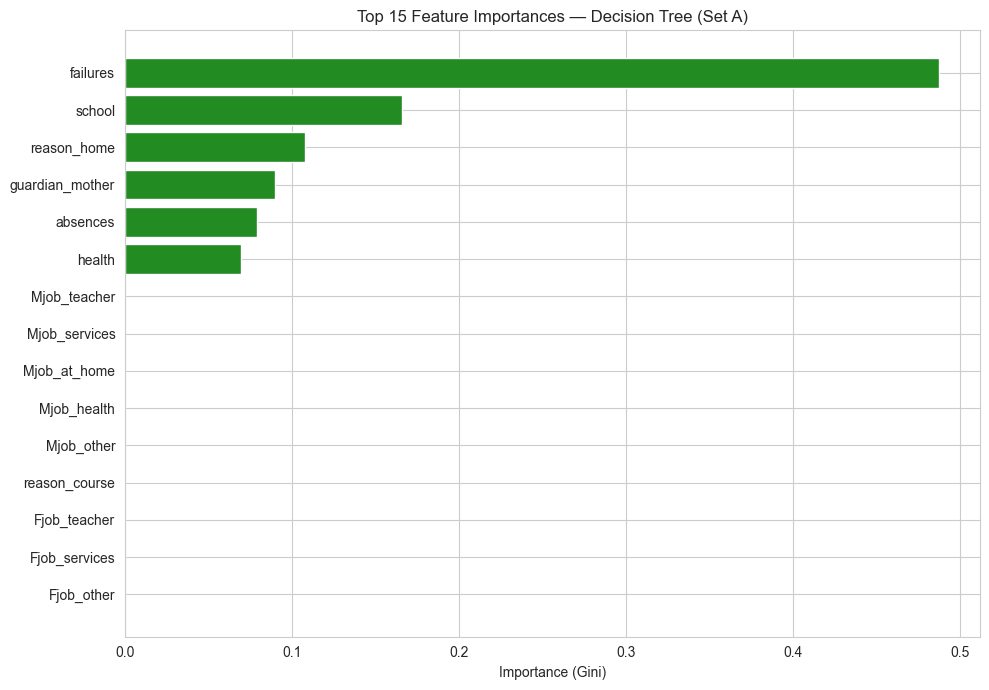

In [29]:
# ============================================================
# Feature Importances — Decision Tree
# ============================================================

# Get feature names post-preprocessing
feature_names = []
feature_names += list(
    tuned_pipe.named_steps['preprocessor']
    .named_transformers_['nom'].named_steps['onehot']
    .get_feature_names_out(nominal_cols)
)
feature_names += ordinal_cols
feature_names += binary_cols
feature_names += numeric_cols

importances = tuned_pipe.named_steps['classifier'].feature_importances_

importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
}).sort_values('importance', ascending=False).reset_index(drop=True)

print("Top 15 Feature Importances — Decision Tree (Set A):")
print(importance_df.head(15).round(4).to_string(index=False))

# Visualization
fig, ax = plt.subplots(figsize=(10, 7))
top_15 = importance_df.head(15)
ax.barh(top_15['feature'][::-1], top_15['importance'][::-1], color='forestgreen')
ax.set_xlabel('Importance (Gini)')
ax.set_title('Top 15 Feature Importances — Decision Tree (Set A)')
plt.tight_layout()
plt.show()

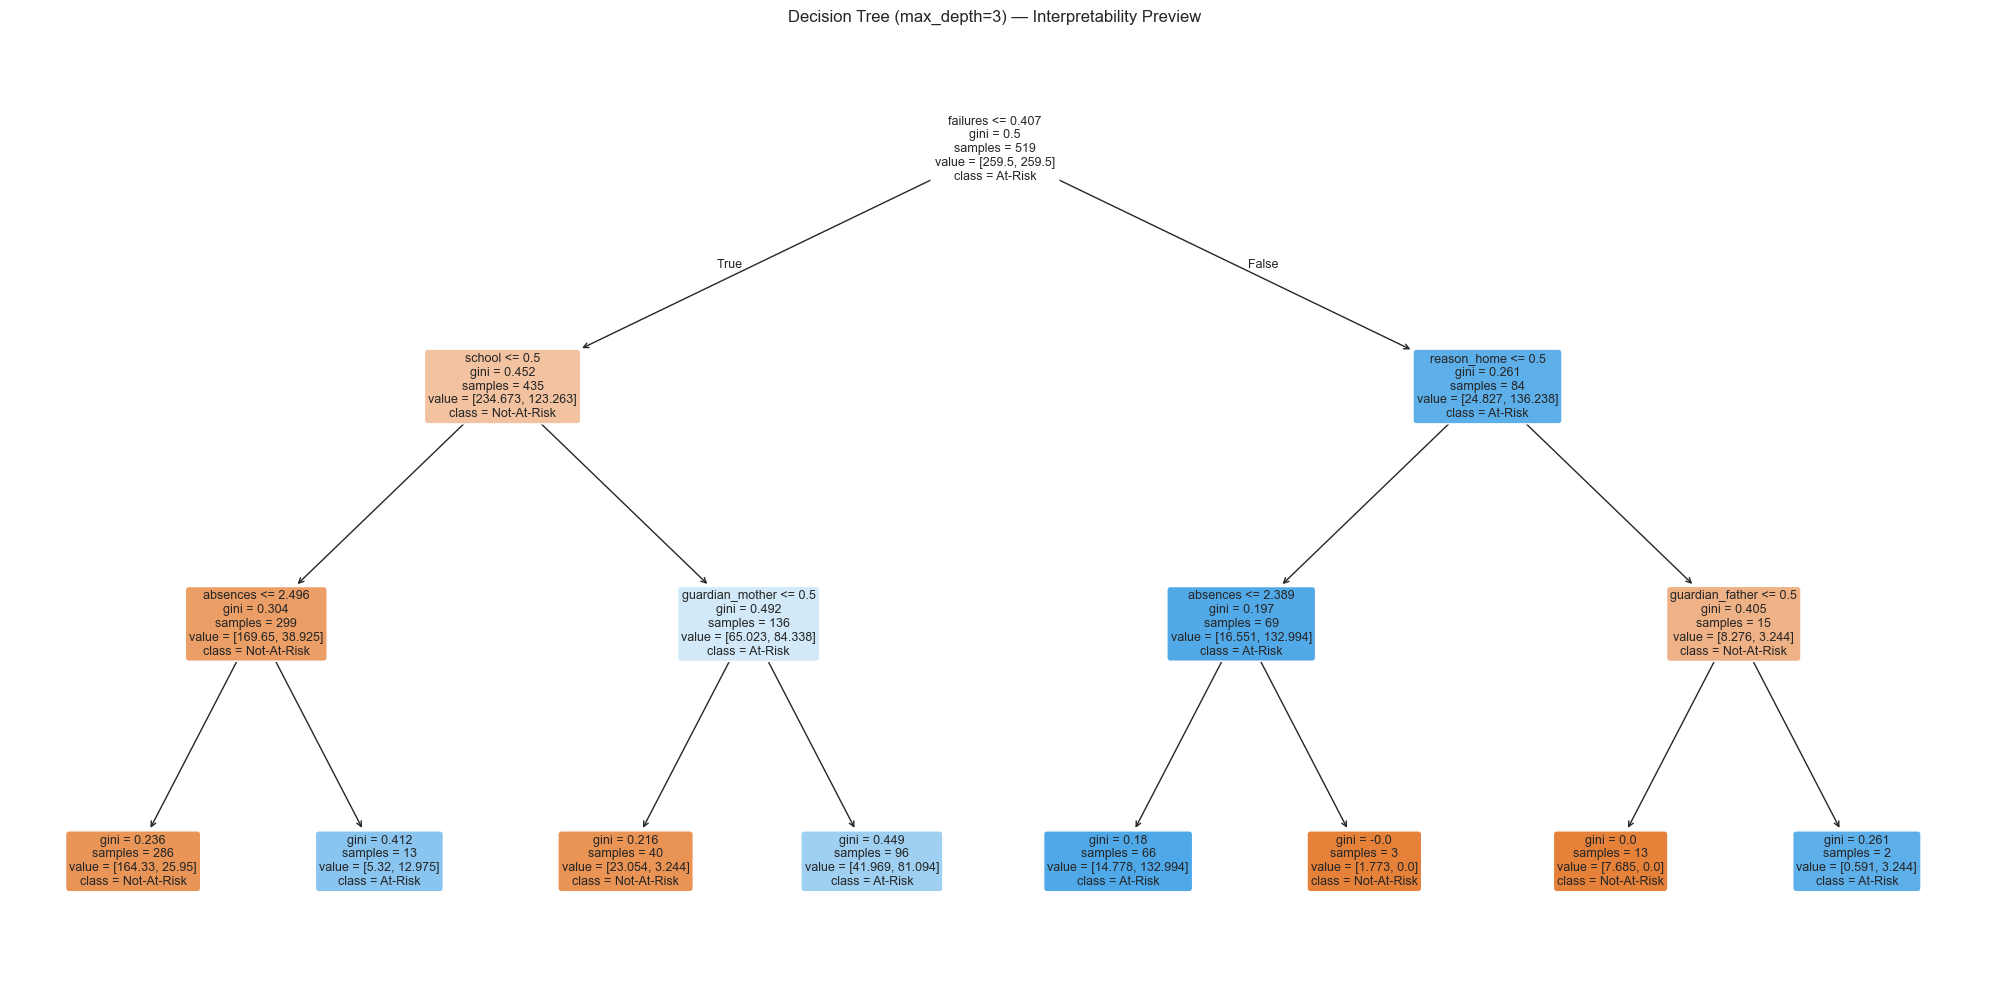

In [30]:
# ============================================================
# Decision Tree Visualization (top 3 levels)
# ============================================================

# Fit a shallow tree for visual interpretation
shallow_tree = Pipeline([
    ('preprocessor', preprocessor_A),
    ('classifier', DecisionTreeClassifier(max_depth=3, random_state=RANDOM_SEED, class_weight='balanced'))
])
shallow_tree.fit(X_por_train, y_por_train)

# Get transformed feature names
shallow_names = []
shallow_names += list(
    shallow_tree.named_steps['preprocessor']
    .named_transformers_['nom'].named_steps['onehot']
    .get_feature_names_out(nominal_cols)
)
shallow_names += ordinal_cols + binary_cols + numeric_cols

fig, ax = plt.subplots(figsize=(20, 10))
plot_tree(shallow_tree.named_steps['classifier'],
          feature_names=shallow_names,
          class_names=['Not-At-Risk', 'At-Risk'],
          filled=True, rounded=True, fontsize=9, ax=ax)
plt.title('Decision Tree (max_depth=3) — Interpretability Preview')
plt.tight_layout()
plt.show()

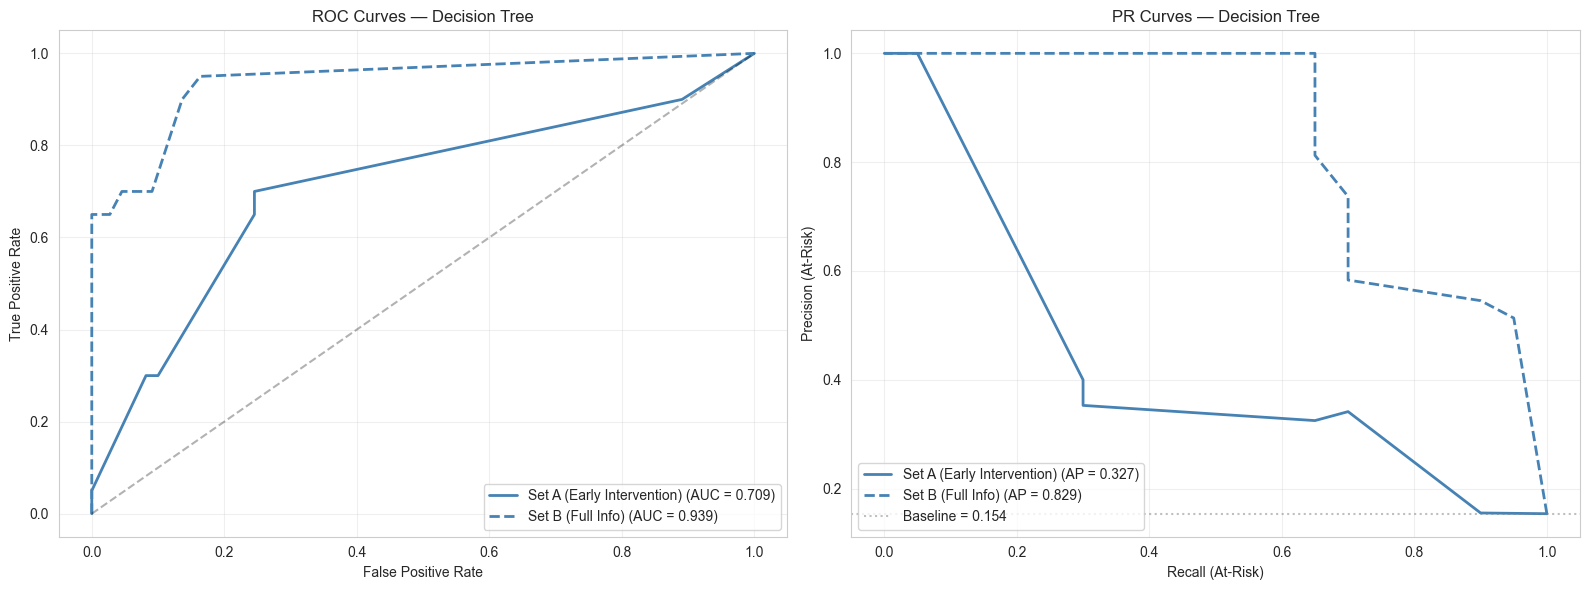

In [31]:
# ============================================================
# ROC and PR Curves — Set A vs Set B
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ROC
ax = axes[0]
for label, y_true, y_proba, color, ls in [
    ('Set A (Early Intervention)', y_por_test, y_test_proba, 'steelblue', '-'),
    ('Set B (Full Info)', y_por_test, y_test_proba_B, 'steelblue', '--'),
]:
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    ax.plot(fpr, tpr, color=color, linestyle=ls, linewidth=2,
            label=f'{label} (AUC = {auc(fpr, tpr):.3f})')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.3)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves — Decision Tree')
ax.legend()
ax.grid(alpha=0.3)

# PR
ax = axes[1]
for label, y_true, y_proba, color, ls in [
    ('Set A (Early Intervention)', y_por_test, y_test_proba, 'steelblue', '-'),
    ('Set B (Full Info)', y_por_test, y_test_proba_B, 'steelblue', '--'),
]:
    prec, rec, _ = precision_recall_curve(y_true, y_proba)
    ap = average_precision_score(y_true, y_proba)
    ax.plot(rec, prec, color=color, linestyle=ls, linewidth=2,
            label=f'{label} (AP = {ap:.3f})')
ax.axhline(y_por_test.mean(), color='gray', linestyle=':', alpha=0.5,
           label=f'Baseline = {y_por_test.mean():.3f}')
ax.set_xlabel('Recall (At-Risk)')
ax.set_ylabel('Precision (At-Risk)')
ax.set_title('PR Curves — Decision Tree')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [32]:
# ============================================================
# Decision Tree — Results Summary
# ============================================================

summary = pd.DataFrame([
    {'Model': 'Baseline', 'Dataset': 'Portuguese', 'Set': 'A', 'Threshold': 0.50, **baseline_metrics},
    {'Model': 'DT (default)', 'Dataset': 'Portuguese', 'Set': 'A', 'Threshold': 0.50, **dt_default_metrics},
    {'Model': 'DT (tuned)', 'Dataset': 'Portuguese', 'Set': 'A', 'Threshold': OPTIMAL_THRESHOLD, **dt_A_metrics},
    {'Model': 'DT (tuned)', 'Dataset': 'Portuguese', 'Set': 'B', 'Threshold': OPTIMAL_THRESHOLD_B, **dt_B_metrics},
    {'Model': 'DT (tuned)', 'Dataset': 'Math', 'Set': 'A', 'Threshold': OPTIMAL_THRESHOLD_MATH, **dt_math_metrics},
])

summary = summary[['Model', 'Dataset', 'Set', 'Threshold',
                   'accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'pr_auc']]

print("=" * 100)
print("DECISION TREE — RESULTS SUMMARY")
print("=" * 100)
print(summary.round(4).to_string(index=False))

DECISION TREE — RESULTS SUMMARY
       Model    Dataset Set  Threshold  accuracy  precision  recall     f1  roc_auc  pr_auc
    Baseline Portuguese   A       0.50    0.8462     0.0000  0.0000 0.0000   0.5000  0.1538
DT (default) Portuguese   A       0.50    0.7615     0.1765  0.1500 0.1622   0.5114  0.1572
  DT (tuned) Portuguese   A       0.20    0.7385     0.3250  0.6500 0.4333   0.7089  0.3272
  DT (tuned) Portuguese   B       0.50    0.8769     0.5833  0.7000 0.6364   0.9389  0.8293
  DT (tuned)       Math   A       0.15    0.4430     0.3594  0.8846 0.5111   0.5751  0.3816


In [33]:
# ============================================================
# Save Decision Tree Results for Group Report
# ============================================================
import json

dt_results = {
    'model': 'Decision Tree (tuned)',
    'member': 'Herath H.M.S.N.W (IT24104159)',
    'portuguese_set_A': {
        'threshold': OPTIMAL_THRESHOLD,
        'best_params': best_params,
        **{k: round(v, 4) for k, v in dt_A_metrics.items()}
    },
    'portuguese_set_B': {
        'threshold': OPTIMAL_THRESHOLD_B,
        'best_params': best_params_B,
        **{k: round(v, 4) for k, v in dt_B_metrics.items()}
    },
    'math_set_A': {
        'threshold': OPTIMAL_THRESHOLD_MATH,
        'best_params': best_params_math,
        **{k: round(v, 4) for k, v in dt_math_metrics.items()}
    },
    'top_5_features': importance_df.head(5).to_dict(orient='records')
}

print(json.dumps(dt_results, indent=2, default=str))

{
  "model": "Decision Tree (tuned)",
  "member": "Herath H.M.S.N.W (IT24104159)",
  "portuguese_set_A": {
    "threshold": 0.2,
    "best_params": {
      "min_samples_split": 20,
      "min_samples_leaf": 2,
      "max_features": null,
      "max_depth": 3,
      "criterion": "entropy",
      "class_weight": null,
      "ccp_alpha": 0.005
    },
    "accuracy": 0.7385,
    "precision": 0.325,
    "recall": 0.65,
    "f1": 0.4333,
    "roc_auc": 0.7089,
    "pr_auc": 0.3272
  },
  "portuguese_set_B": {
    "threshold": 0.5,
    "best_params": {
      "min_samples_split": 5,
      "min_samples_leaf": 10,
      "max_features": null,
      "max_depth": 20,
      "criterion": "entropy",
      "class_weight": null,
      "ccp_alpha": 0.001
    },
    "accuracy": 0.8769,
    "precision": 0.5833,
    "recall": 0.7,
    "f1": 0.6364,
    "roc_auc": 0.9389,
    "pr_auc": 0.8293
  },
  "math_set_A": {
    "threshold": 0.15,
    "best_params": {
      "min_samples_split": 20,
      "min_samples_

In [34]:
print("Portuguese model fitted:",
      hasattr(tuned_pipe, "classes_")
      or hasattr(tuned_pipe.named_steps["classifier"], "classes_"))

print("Mathematics model fitted:",
      hasattr(tuned_pipe_math.named_steps["classifier"], "classes_"))

print("Portuguese threshold:", OPTIMAL_THRESHOLD)
print("Mathematics threshold:", OPTIMAL_THRESHOLD_MATH)

Portuguese model fitted: True
Mathematics model fitted: True
Portuguese threshold: 0.2
Mathematics threshold: 0.15


In [35]:

from pathlib import Path
import joblib
import json

# Locate the project root
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save the fitted Feature Set A pipelines
models_to_save = {
    "decision_tree_portuguese_tuned.joblib": tuned_pipe,
    "decision_tree_mathematics_tuned.joblib": tuned_pipe_math,
}

for filename, model in models_to_save.items():
    output_path = MODEL_DIR / filename
    joblib.dump(model, output_path)
    print(f"Saved: {output_path}")

# Save the classification thresholds
thresholds = {
    "portuguese": float(OPTIMAL_THRESHOLD),
    "mathematics": float(OPTIMAL_THRESHOLD_MATH),
}

threshold_path = MODEL_DIR / "decision_tree_thresholds.json"

with open(threshold_path, "w", encoding="utf-8") as file:
    json.dump(thresholds, file, indent=4)

print("\nThresholds saved:", threshold_path)
print("Decision Tree model saving complete!")


Saved: c:\Users\USER\student-risk-intelligence\models\decision_tree_portuguese_tuned.joblib
Saved: c:\Users\USER\student-risk-intelligence\models\decision_tree_mathematics_tuned.joblib

Thresholds saved: c:\Users\USER\student-risk-intelligence\models\decision_tree_thresholds.json
Decision Tree model saving complete!
